In [1]:
import sys
from pathlib import Path

# Obtiene la ruta absoluta de la raíz del proyecto (sube un nivel desde 'notebooks/')
# Ajusta .parent según dónde esté guardado tu notebook
project_root = Path().resolve().parent 
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

In [2]:
# 1) Importamos las librerías con sus alias convencionales
import pandas as pd                 # tablas (DataFrame)
import numpy as np                  # cálculo numérico y condiciones vectorizadas
import matplotlib.pyplot as plt     # gráficos base (Seaborn se apoya en él)
import seaborn as sns               # gráficos estadísticos de alto nivel
from scipy import stats             # pruebas estadísticas (Parte 6)

from flows.common.paths import BRONZE, SILVER, GOLD, BRONZE_LABELED_NAME, SILVER_NAME

# 2) Estilo global: todos los gráficos heredan esta configuración
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (8, 5)   # tamaño por defecto (ancho, alto) en pulgadas
plt.rcParams['axes.titlesize'] = 13

# 3) Cargamos Bronze (nunca la URL: la ingesta ya la guardó)
df = pd.read_csv(BRONZE / BRONZE_LABELED_NAME)

In [3]:
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0.0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1.0,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0.0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1.0,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [4]:
df.shape

(891, 12)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    float64
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(3), int64(4), str(5)
memory usage: 118.9 KB


In [6]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [7]:
df.select_dtypes(exclude='number').describe()

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


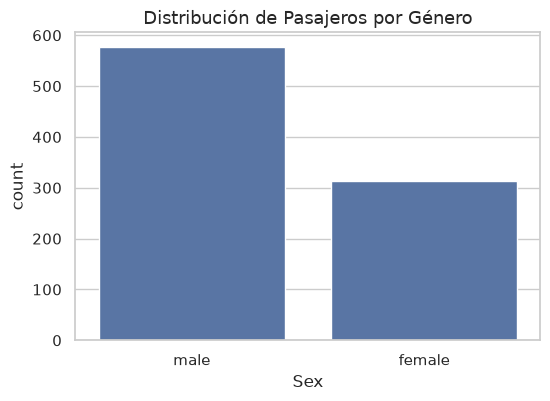

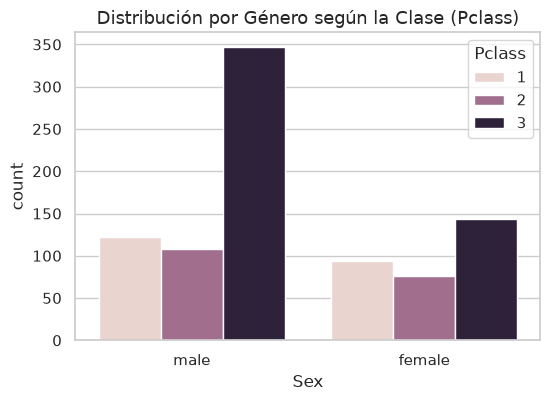

Pclass         1         2         3
Sex                                 
female  0.435185  0.413043  0.293279
male    0.564815  0.586957  0.706721


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico de conteo de 'Sex'
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex')
plt.title('Distribución de Pasajeros por Género')
plt.show()

# 2. Gráfico de conteo de 'Sex' con hue='Pclass'
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Sex', hue='Pclass')
plt.title('Distribución por Género según la Clase (Pclass)')
plt.show()

# 3. Tabla cruzada Sex x Pclass NORMALIZADA POR COLUMNAS
crosstab_norm = pd.crosstab(df['Sex'], df['Pclass'], normalize='columns')
print(crosstab_norm)

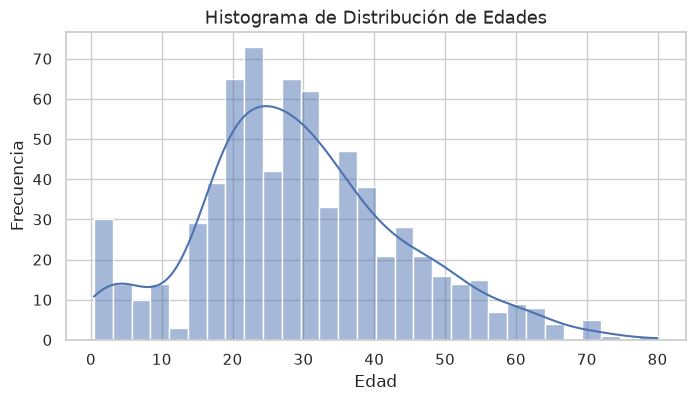

Edad promedio: 29.69911764705882
Mediana de la edad: 28.0
Edad mínima: 0.42
Edad máxima: 80.0


In [9]:
# 1. Histograma de la edad ignorando nulos con dropna()
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'].dropna(), bins=30, kde=True)
plt.title('Histograma de Distribución de Edades')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

# 2. Edad promedio (Media)
promedio_edad = df['Age'].mean()
print(f"Edad promedio: {promedio_edad}")

# 3. Mediana, mínimo y máximo de la edad
print(f"Mediana de la edad: {df['Age'].median()}")
print(f"Edad mínima: {df['Age'].min()}")
print(f"Edad máxima: {df['Age'].max()}")

In [10]:
import importlib

# Importamos dinámicamente el módulo de ingeniería de datos
de = importlib.import_module("flows.01_data_engineering")

# Aplicamos la función al DataFrame
df = de.add_person(df)

# Realizamos el conteo sin errores
conteo_personas = df['Person'].value_counts()
print(conteo_personas)

Person
male      537
female    271
child      83
Name: count, dtype: int64


In [11]:
# Paso 9: Tabla cruzada de 'Pclass' (filas) contra 'Person' (columnas)
tabla_clase_persona = pd.crosstab(df['Pclass'], df['Person'])
print(tabla_clase_persona)

Person  child  female  male
Pclass                     
1           6      91   119
2          19      66    99
3          58     114   319


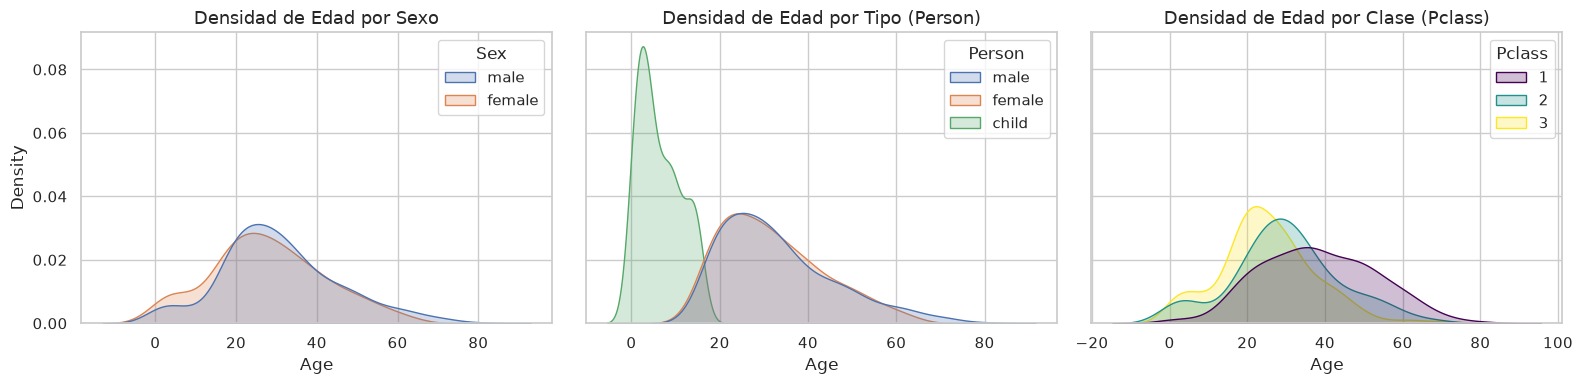

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paso 10: Gráficos de densidad (KDE) de la edad por diferentes categorías
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

# Gráfico 1: KDE de Age agrupado por Sex
sns.kdeplot(data=df, x='Age', hue='Sex', fill=True, common_norm=False, ax=axes[0])
axes[0].set_title('Densidad de Edad por Sexo')

# Gráfico 2: KDE de Age agrupado por Person
sns.kdeplot(data=df, x='Age', hue='Person', fill=True, common_norm=False, ax=axes[1])
axes[1].set_title('Densidad de Edad por Tipo (Person)')

# Gráfico 3: KDE de Age agrupado por Pclass
sns.kdeplot(data=df, x='Age', hue='Pclass', fill=True, common_norm=False, palette='viridis', ax=axes[2])
axes[2].set_title('Densidad de Edad por Clase (Pclass)')

plt.tight_layout()
plt.show()

In [13]:
import importlib

de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

df = de.add_cabin_features(df)

conteo_cabinas = df['TCabin'].value_counts()
print(conteo_cabinas)

TCabin
X    687
C     59
B     47
D     33
E     32
A     15
F     13
G      4
T      1
Name: count, dtype: int64


/tmp/ipykernel_131318/920684016.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=cubierta_filtrada, order=sorted(cubierta_filtrada.unique()), palette='viridis')


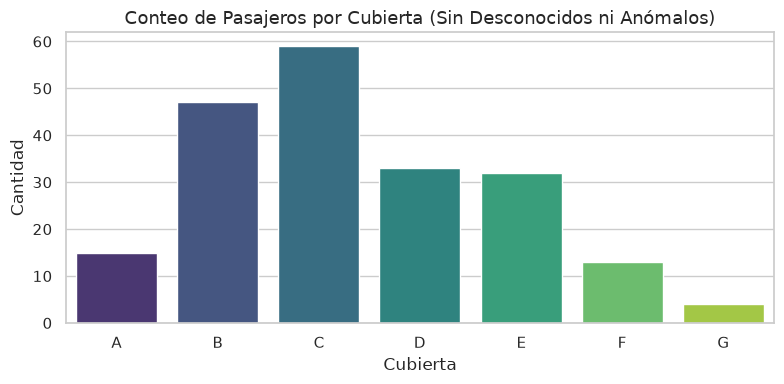

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtramos solo las cabinas conocidas (excluyendo 'X') y excluimos el valor anómalo 'T' solo para el gráfico
cubierta_filtrada = df.loc[(df['TCabin'] != 'X') & (df['TCabin'] != 'T'), 'TCabin']

# 2. Generamos el gráfico de conteo (countplot)
plt.figure(figsize=(8, 4))
sns.countplot(x=cubierta_filtrada, order=sorted(cubierta_filtrada.unique()), palette='viridis')

plt.title('Conteo de Pasajeros por Cubierta (Sin Desconocidos ni Anómalos)')
plt.xlabel('Cubierta')
plt.ylabel('Cantidad')
plt.tight_layout()
plt.show()

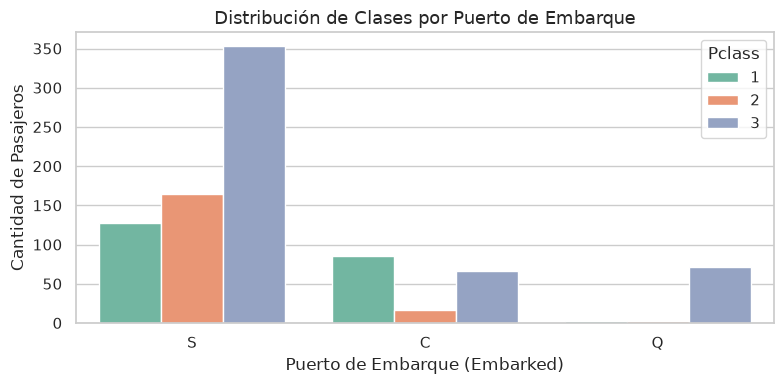

--- Porcentaje de Clases por Puerto de Embarque (%) ---
Pclass        1      2      3
Embarked                     
C         50.60  10.12  39.29
Q          2.60   3.90  93.51
S         19.72  25.47  54.81


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Gráfico de conteo de 'Embarked' agrupado por 'Pclass' (con hue='Pclass')
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Embarked', hue='Pclass', palette='Set2')
plt.title('Distribución de Clases por Puerto de Embarque')
plt.xlabel('Puerto de Embarque (Embarked)')
plt.ylabel('Cantidad de Pasajeros')
plt.legend(title='Pclass')
plt.tight_layout()
plt.show()

# 2. Tabla cruzada de Embarked x Pclass normalizada por FILAS (normalize='index')
tabla_embarque_clase = pd.crosstab(df['Embarked'], df['Pclass'], normalize='index') * 100
print("--- Porcentaje de Clases por Puerto de Embarque (%) ---")
print(tabla_embarque_clase.round(2))

In [16]:
import importlib

# Recargamos el módulo para que tome la nueva función de familia/alone
de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

# Aplicamos la función al DataFrame
df = de.add_family_features(df)

# Calculamos la proporción de cada categoría
proporcion_alone = df['Alone'].value_counts(normalize=True) * 100
print("--- Proporción de Pasajeros (Alone vs with Family) ---")
print(proporcion_alone.round(2))

--- Proporción de Pasajeros (Alone vs with Family) ---
Alone
Alone          60.27
with Family    39.73
Name: proportion, dtype: float64


/tmp/ipykernel_131318/425655831.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Alone', palette='Set2')


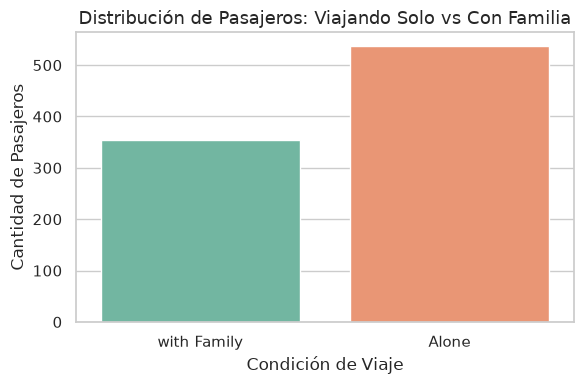

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Alone', palette='Set2')
plt.title('Distribución de Pasajeros: Viajando Solo vs Con Familia')
plt.xlabel('Condición de Viaje')
plt.ylabel('Cantidad de Pasajeros')
plt.tight_layout()
plt.show()

/tmp/ipykernel_131318/51001724.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survivor', palette='Set2')


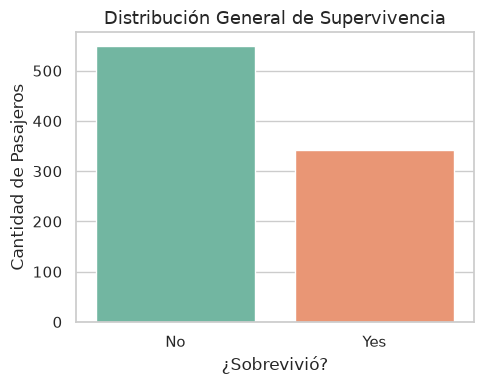

--- Tasa General de Supervivencia ---
38.38% (Debe rondar el 38%)


In [18]:
import importlib
import matplotlib.pyplot as plt
import seaborn as sns

# Recargamos el módulo para que tome la nueva función de supervivencia
de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

# Aplicamos la función al DataFrame
df = de.add_survivor_label(df)

# Gráfico de conteo de 'Survivor'
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='Survivor', palette='Set2')
plt.title('Distribución General de Supervivencia')
plt.xlabel('¿Sobrevivió?')
plt.ylabel('Cantidad de Pasajeros')
plt.tight_layout()
plt.show()

# Calculamos la tasa general de supervivencia (media de 'Survived')
tasa_supervivencia = df['Survived'].mean() * 100
print(f"--- Tasa General de Supervivencia ---")
print(f"{tasa_supervivencia:.2f}% (Debe rondar el 38%)")

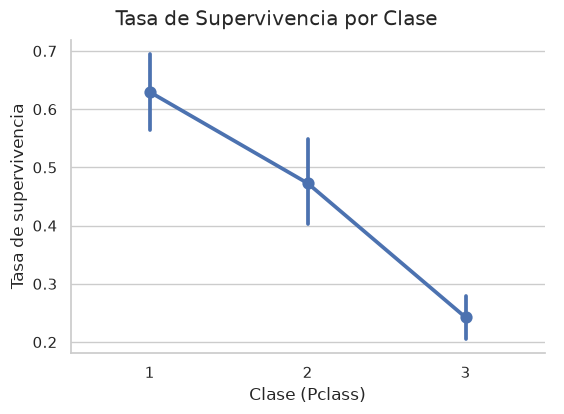

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Paso 17: Gráfico de puntos de supervivencia por clase
g = sns.catplot(data=df, x='Pclass', y='Survived', kind='point', height=4, aspect=1.4)
g.fig.suptitle('Tasa de Supervivencia por Clase', y=1.03)
g.set_axis_labels('Clase (Pclass)', 'Tasa de supervivencia')
plt.show()

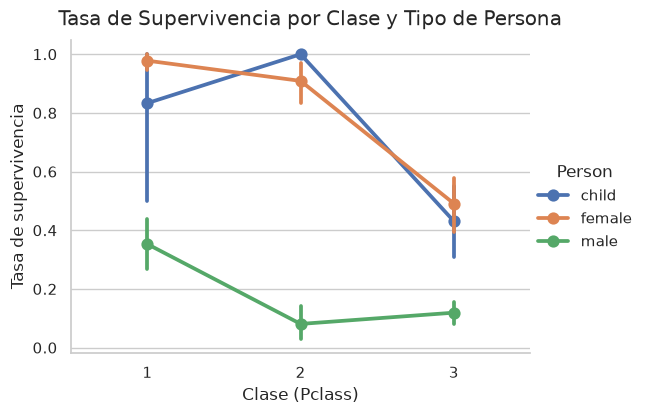

In [20]:
# Paso 18: Supervivencia por clase y tipo de persona
g = sns.catplot(
    data=df, 
    x='Pclass', 
    y='Survived', 
    hue='Person', 
    hue_order=['child', 'female', 'male'], 
    kind='point', 
    height=4, 
    aspect=1.4
)
g.fig.suptitle('Tasa de Supervivencia por Clase y Tipo de Persona', y=1.03)
g.set_axis_labels('Clase (Pclass)', 'Tasa de supervivencia')
plt.show()

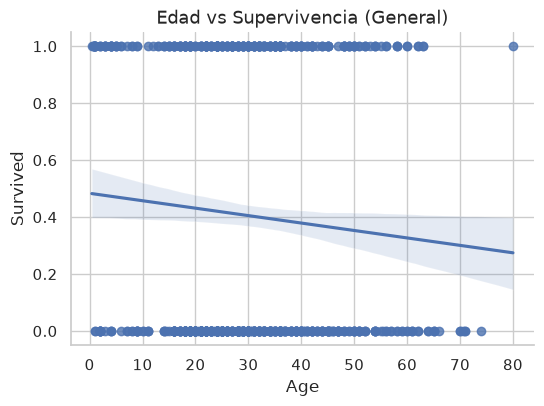

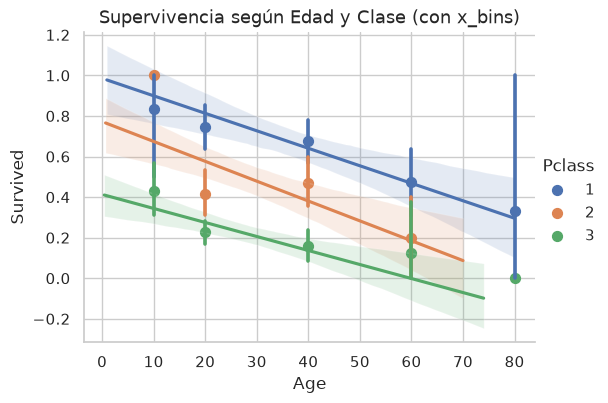

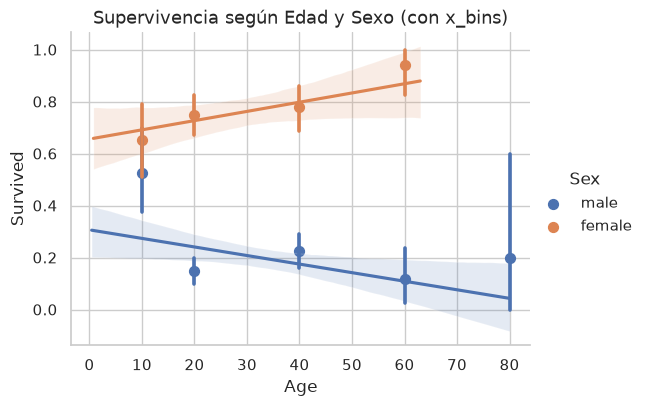

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

# Definimos los límites de los bins generacionales según la guía
generaciones = [10, 20, 40, 60, 80]

# 1. Gráfico básico de lmplot de Edad vs Supervivencia
sns.lmplot(data=df, x='Age', y='Survived', height=4, aspect=1.4)
plt.title('Edad vs Supervivencia (General)')
plt.show()

# 2 y 3. Usando x_bins con generaciones y agrupando por Pclass
sns.lmplot(data=df, x='Age', y='Survived', hue='Pclass', x_bins=generaciones, height=4, aspect=1.4)
plt.title('Supervivencia según Edad y Clase (con x_bins)')
plt.show()

# 4. Repitiendo el punto 3 pero agrupando por Sex
sns.lmplot(data=df, x='Age', y='Survived', hue='Sex', x_bins=generaciones, height=4, aspect=1.4)
plt.title('Supervivencia según Edad y Sexo (con x_bins)')
plt.show()

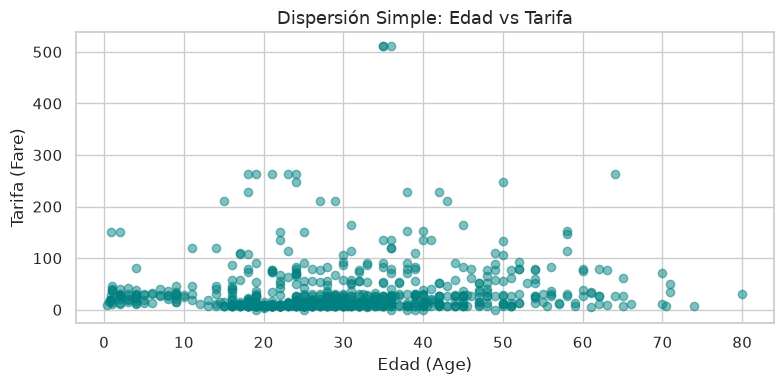

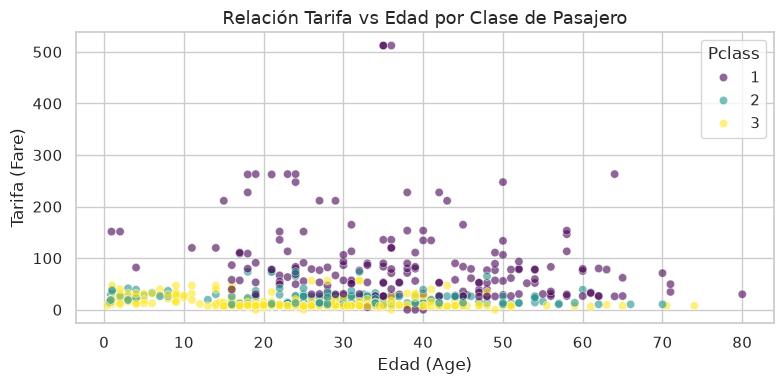

In [22]:
# 1. Dispersión simple de Edad vs Tarifa
plt.figure(figsize=(8, 4))
plt.scatter(df['Age'], df['Fare'], alpha=0.5, color='teal')
plt.title('Dispersión Simple: Edad vs Tarifa')
plt.xlabel('Edad (Age)')
plt.ylabel('Tarifa (Fare)')
plt.tight_layout()
plt.show()

# 2. Desafío: Scatterplot avanzado agrupado por Pclass con paleta de colores
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='Age', y='Fare', hue='Pclass', alpha=0.6, palette='viridis')
plt.title('Relación Tarifa vs Edad por Clase de Pasajero')
plt.xlabel('Edad (Age)')
plt.ylabel('Tarifa (Fare)')
plt.legend(title='Pclass')
plt.tight_layout()
plt.show()

In [24]:
import importlib

# Recargamos el módulo para tomar las nuevas funciones
de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

# 1. Verificamos cuántos valores faltan en 'Embarked' inicialmente
faltantes_antes = df['Embarked'].isna().sum()
print(f"Valores faltantes en 'Embarked' antes de imputar: {faltantes_antes}")

# 2 y 3. Aplicamos la imputación
df = de.impute_embarked(df)
faltantes_despues = df['Embarked'].isna().sum()
print(f"Valores faltantes en 'Embarked' después de imputar: {faltantes_despues}")

# 4. Aplicamos la codificación categórica para crear 'NEmbarked'
df = de.encode_categoricals(df)

# Verificamos los primeros registros de la nueva columna codificada
print("\n--- Verificación de NEmbarked ---")
print(df[['Embarked', 'NEmbarked']].drop_duplicates())

Valores faltantes en 'Embarked' antes de imputar: 0
Valores faltantes en 'Embarked' después de imputar: 0

--- Verificación de NEmbarked ---
  Embarked  NEmbarked
0        S          0
1        C          1
5        Q          2


In [25]:
import importlib

# Recargamos el módulo para tomar la nueva función
de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

# Verificamos valores nulos en 'Age' antes de imputar
nulos_antes = df['Age'].isna().sum()
print(f"Edades faltantes antes de imputar: {nulos_antes}")

# Aplicamos la función de imputación de edad
df = de.impute_age(df)

# Verificamos valores nulos en 'Age' después de imputar
nulos_despues = df['Age'].isna().sum()
print(f"Edades faltantes después de imputar: {nulos_despues}")

# Mostramos un resumen de las nuevas columnas creadas
print("\n--- Verificación de columnas de edad ---")
print(df[['AgeOriginal', 'Age', 'AgeImputada', 'Sex']].head(10))

Edades faltantes antes de imputar: 177
Edades faltantes después de imputar: 0

--- Verificación de columnas de edad ---
   AgeOriginal        Age  AgeImputada     Sex
0         22.0  22.000000        False    male
1         38.0  38.000000        False  female
2         26.0  26.000000        False  female
3         35.0  35.000000        False  female
4         35.0  35.000000        False    male
5          NaN  30.726645         True    male
6         54.0  54.000000        False    male
7          2.0   2.000000        False    male
8         27.0  27.000000        False  female
9         14.0  14.000000        False  female


In [26]:
import logging

# Configuramos el nivel de logging por si no está activo en el cuaderno
logging.basicConfig(level=logging.INFO)

# Calculamos la desviación estándar antes (AgeOriginal) y después (Age)
std_antes = df['AgeOriginal'].std()
std_despues = df['Age'].std()

# Registramos usando log.info como pide el reto
logging.info(f"Desviación estándar de la edad antes de imputar: {std_antes:.4f}")
logging.info(f"Desviación estándar de la edad después de imputar: {std_despues:.4f}")

print(f"Std antes: {std_antes:.4f}")
print(f"Std despues: {std_despues:.4f}")

INFO:root:Desviación estándar de la edad antes de imputar: 14.5265
INFO:root:Desviación estándar de la edad después de imputar: 13.0149


Std antes: 14.5265
Std despues: 13.0149


In [27]:
import importlib

# Recargamos el módulo para tomar las nuevas actualizaciones
de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

# Aplicamos la función
df = de.encode_categoricals(df)

# Verificamos los resultados de NSex
print("--- Verificación de NSex ---")
print(df[['Sex', 'NSex']].drop_duplicates())

# Verificamos los resultados de NCabin y TCabin
print("\n--- Verificación de NCabin ---")
print(df[['TCabin', 'NCabin']].drop_duplicates().sort_values('NCabin'))

--- Verificación de NSex ---
      Sex  NSex
0    male     1
1  female     0

--- Verificación de NCabin ---
    TCabin  NCabin
23       A       0
31       B       1
1        C       2
21       D       3
6        E       4
66       F       5
10       G       6
339      T       7
0        X       8


In [29]:
import importlib

# Recargamos el módulo para tomar la nueva función
de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

# 1. Aplicamos la función para crear 'TTitulo'
df = de.add_title(df)

# 2. Analizamos la frecuencia de cada título
print("--- Frecuencia de Títulos (value_counts) ---")
print(df['TTitulo'].value_counts())

# 3. Tabla cruzada de título vs. género
print("\n--- Tabla Cruzada: Título vs. Género ---")
print(pd.crosstab(df['TTitulo'], df['Sex']))

--- Frecuencia de Títulos (value_counts) ---
TTitulo
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

--- Tabla Cruzada: Título vs. Género ---
Sex           female  male
TTitulo                   
Capt               0     1
Col                0     2
Don                0     1
Dr                 1     6
Jonkheer           0     1
Lady               1     0
Major              0     2
Master             0    40
Miss             182     0
Mlle               2     0
Mme                1     0
Mr                 0   517
Mrs              125     0
Ms                 1     0
Rev                0     6
Sir                0     1
the Countess       1     0


In [30]:
import importlib

# Recargamos el módulo
de = importlib.import_module("flows.01_data_engineering")
importlib.reload(de)

# Aplicamos consolidación y codificación
df = de.consolidate_titles(df)
df = de.encode_categoricals(df)

# Revisamos los conteos finales
print("--- Conteos Finales de TTitulo Consolidados ---")
print(df['TTitulo'].value_counts())

print("\n--- Verificación de NTitulo ---")
print(df[['TTitulo', 'NTitulo']].drop_duplicates())

--- Conteos Finales de TTitulo Consolidados ---
TTitulo
Mr      557
Miss    186
Mrs     127
Otro     21
Name: count, dtype: int64

--- Verificación de NTitulo ---
   TTitulo  NTitulo
0       Mr        0
1      Mrs        1
2     Miss        2
30    Otro        3


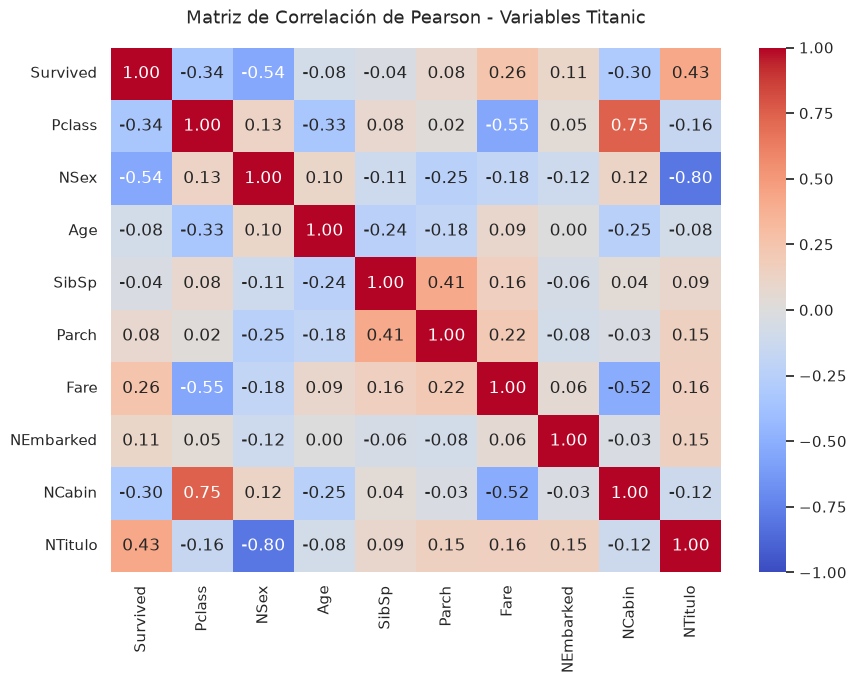

--- Correlación respecto a la Supervivencia (Survived) ---
NSex        -0.543351
Pclass      -0.338481
NCabin      -0.301116
Age         -0.080453
SibSp       -0.035322
Parch        0.081629
NEmbarked    0.106811
Fare         0.257307
NTitulo      0.428661
Survived     1.000000
Name: Survived, dtype: float64


In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Elige las variables numéricas relevantes según la guía
cols = ['Survived', 'Pclass', 'NSex', 'Age', 'SibSp', 'Parch', 'Fare', 'NEmbarked', 'NCabin', 'NTitulo']

# 2. Calcula la matriz de correlación de Pearson
corr = df[cols].corr()

# 3. Dibuja el mapa de calor (heatmap) para hacerla legible
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Matriz de Correlación de Pearson - Variables Titanic', y=1.03)
plt.tight_layout()
plt.show()

# 4. Imprime únicamente la columna de correlaciones con 'Survived' ordenada de menor a mayor
print("--- Correlación respecto a la Supervivencia (Survived) ---")
print(corr['Survived'].sort_values())

In [32]:
import importlib

# Importamos y recargamos el nuevo módulo de agregación de la capa Gold
agg = importlib.import_module("flows.03_aggregation")
importlib.reload(agg)

# Generamos el diccionario de tablas estadísticas
tablas_gold = agg.group_stats(df)

# Imprimimos cada una de las tablas para verificar
for nombre, tabla in tablas_gold.items():
    print(f"================ {nombre.upper()} ================")
    print(tabla)
    print("\n")

================ AGE_BY_SURVIVAL ================
   Survived  count       mean        std   min   25%        50%   75%   max
0       0.0  549.0  30.562012  12.460355  1.00  23.0  30.726645  35.0  74.0
1       1.0  342.0  28.410122  13.774087  0.42  21.0  27.915709  35.0  80.0


================ SURVIVAL_BY_SEX ================
      Sex      mean    sum  count
0  female  0.742038  233.0    314
1    male  0.188908  109.0    577


================ SURVIVAL_BY_PCLASS ================
   Pclass      mean    sum  count
0       1  0.629630  136.0    216
1       2  0.472826   87.0    184
2       3  0.242363  119.0    491


================ SURVIVAL_BY_ALONE ================
         Alone      mean    sum  count
0        Alone  0.303538  163.0    537
1  with Family  0.505650  179.0    354




In [33]:
import importlib

# Recargamos el módulo para que tome la nueva función chi2
agg = importlib.import_module("flows.03_aggregation")
importlib.reload(agg)

# Ejecutamos la prueba chi-cuadrado
resultado_chi2 = agg.chi2_sex_survival(df)

print("--- Resultados Prueba Chi-cuadrado (Sex vs Survived) ---")
print(f"Estadístico Chi2: {resultado_chi2['chi2']:.4f}")
print(f"P-value: {resultado_chi2['p_value']:.4e}")
print(f"Grados de libertad (dof): {resultado_chi2['dof']}")

--- Resultados Prueba Chi-cuadrado (Sex vs Survived) ---
Estadístico Chi2: 260.7170
P-value: 1.1974e-58
Grados de libertad (dof): 1


/tmp/ipykernel_131318/2719939489.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Sex', y='AgeOriginal', ax=axes[0, 0], palette='Set2')
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
/tmp/ipykernel_131318/2719939489.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Pclass', y='AgeOriginal', ax=axes[0, 1], palette='Set2')
INFO:matplotlib.category:Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the a

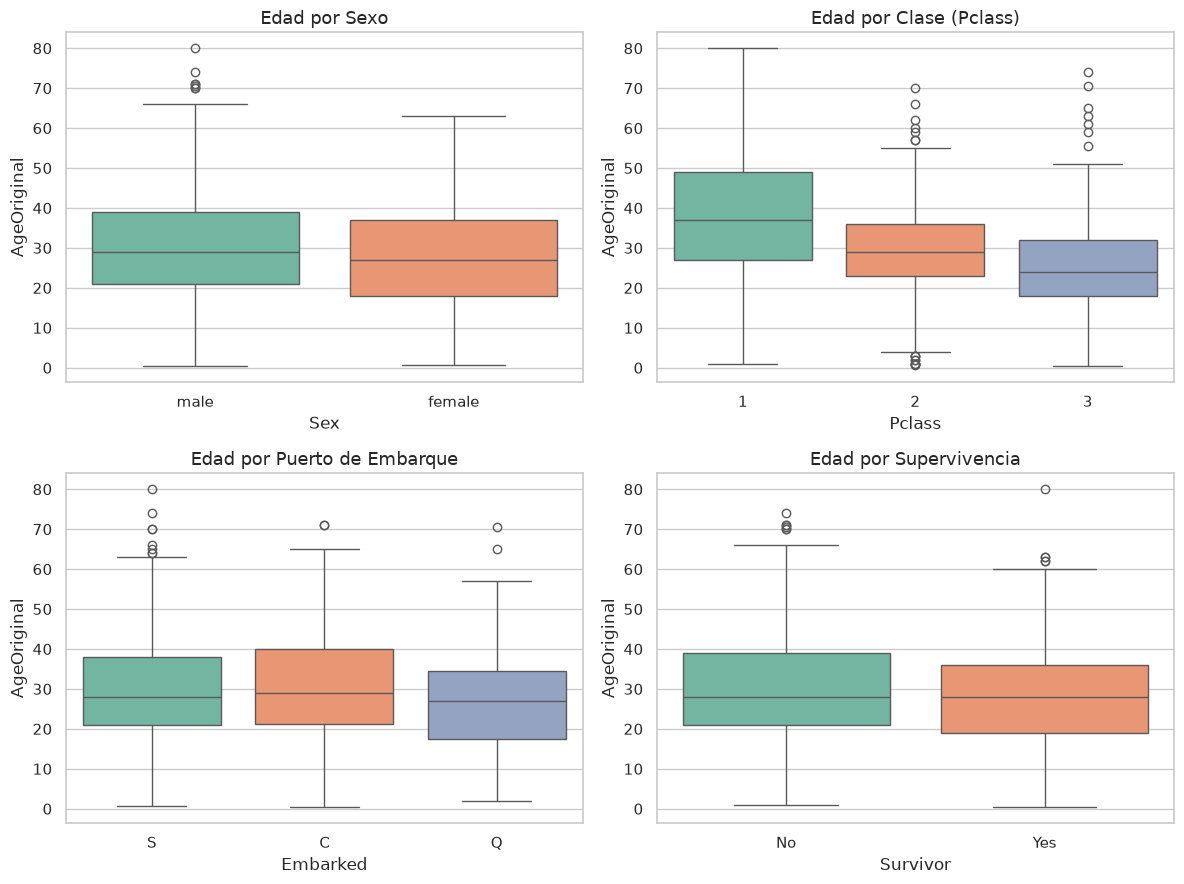

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Creamos la figura y los ejes en una cuadrícula de 2x2
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 2. Dibujamos cada boxplot en su posición correspondiente de la cuadrícula
# Nota: Usamos 'AgeOriginal' para ver solo las edades reales (o 'Age' si prefieres la imputada)
sns.boxplot(data=df, x='Sex', y='AgeOriginal', ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Edad por Sexo')

sns.boxplot(data=df, x='Pclass', y='AgeOriginal', ax=axes[0, 1], palette='Set2')
axes[0, 1].set_title('Edad por Clase (Pclass)')

sns.boxplot(data=df, x='Embarked', y='AgeOriginal', ax=axes[1, 0], palette='Set2')
axes[1, 0].set_title('Edad por Puerto de Embarque')

sns.boxplot(data=df, x='Survivor', y='AgeOriginal', ax=axes[1, 1], palette='Set2')
axes[1, 1].set_title('Edad por Supervivencia')

# 3. Ajustamos el diseño y mostramos la figura
plt.tight_layout()
plt.show()

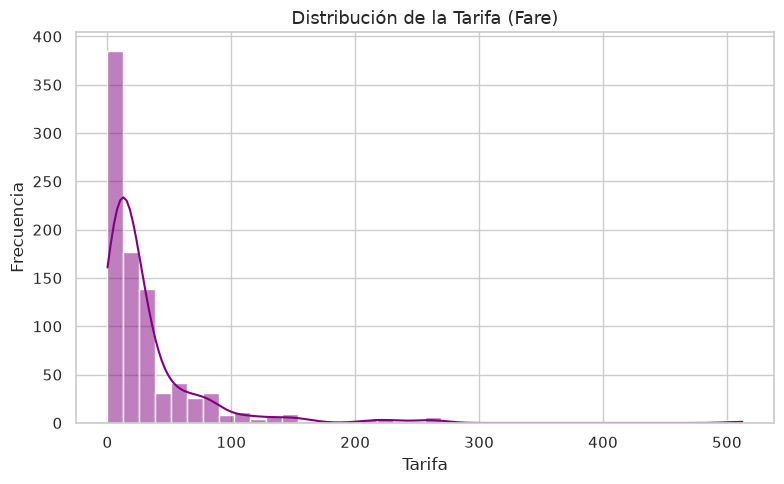

--- Estadísticos de la Tarifa (Fare) ---
Media: 32.20
Mediana: 14.45
Asimetría (Skewness): 4.79


In [35]:
# 1. Histograma con curva KDE para la Tarifa (Fare)
plt.figure(figsize=(8, 5))
sns.histplot(df['Fare'], kde=True, bins=40, color='purple')
plt.title('Distribución de la Tarifa (Fare)')
plt.xlabel('Tarifa')
plt.ylabel('Frecuencia')
plt.tight_layout()
plt.show()

# 2. Calculamos media, mediana y asimetría (skew) de 'Fare'
media_fare = df['Fare'].mean()
mediana_fare = df['Fare'].median()
skew_fare = df['Fare'].skew()

print("--- Estadísticos de la Tarifa (Fare) ---")
print(f"Media: {media_fare:.2f}")
print(f"Mediana: {mediana_fare:.2f}")
print(f"Asimetría (Skewness): {skew_fare:.2f}")